# Multiclass Classificatoin

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, classification_report

import tensorflow as tf

# Parameters

In [2]:
inpDir = '../input'
outDir = '../output'

RANDOM_STATE = 24 # REMEBER : TO REMOVE AT THE TIME OF PROMOTION TO PRODUCTION
np.random.seed(seed=RANDOM_STATE)
tf.random.set_seed(seed=RANDOM_STATE)

EPOCHS = 100
ALPHA = 0.001
TEST_SIZE = 0.2


params = { 'legend.fontsize': 'medium',
           'figure.figsize':(15,6),
           'axes.labelsize':'medium',
           'axes.titlesize':'medium',
           'xtick.labelsize': 'medium',
           'ytick.labelsize': 'medium'
}

plt.rcParams.update(params)
CMAP = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

# Helper Function

In [3]:
physical_devices = tf.config.list_physical_devices('GPU')
physical_devices

[]

In [4]:
if len(physical_devices)>0:
    tf.config.experimental.set_memory_growth(physical_devices[0],True)

# Load Dataset

In [5]:
df = pd.read_csv("wine.csv", header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [6]:
df.shape

(178, 14)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       178 non-null    float64
 1   1       178 non-null    float64
 2   2       178 non-null    float64
 3   3       178 non-null    float64
 4   4       178 non-null    int64  
 5   5       178 non-null    float64
 6   6       178 non-null    float64
 7   7       178 non-null    float64
 8   8       178 non-null    float64
 9   9       178 non-null    float64
 10  10      178 non-null    float64
 11  11      178 non-null    float64
 12  12      178 non-null    int64  
 13  13      178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
0,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
1,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
2,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
3,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
4,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
5,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
6,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
7,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
8,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
9,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [9]:
for col in df.columns:
    print(f"Col: {col}, {df[col].unique()}")

Col: 0, [14.23 13.2  13.16 14.37 13.24 14.2  14.39 14.06 14.83 13.86 14.1  14.12
 13.75 14.75 14.38 13.63 14.3  13.83 14.19 13.64 12.93 13.71 12.85 13.5
 13.05 13.39 13.3  13.87 14.02 13.73 13.58 13.68 13.76 13.51 13.48 13.28
 13.07 14.22 13.56 13.41 13.88 14.21 13.9  13.94 13.82 13.77 13.74 13.29
 13.72 12.37 12.33 12.64 13.67 12.17 13.11 13.34 12.21 12.29 13.49 12.99
 11.96 11.66 13.03 11.84 12.7  12.   12.72 12.08 12.67 12.16 11.65 11.64
 12.69 11.62 12.47 11.81 12.6  12.34 11.82 12.51 12.42 12.25 12.22 11.61
 11.46 12.52 11.76 11.41 11.03 12.77 11.45 11.56 11.87 12.07 12.43 11.79
 12.04 12.86 12.88 12.81 12.53 12.84 13.36 13.52 13.62 12.87 13.32 13.08
 12.79 13.23 12.58 13.17 13.84 12.45 14.34 12.36 13.69 12.96 13.78 13.45
 12.82 13.4  12.2  14.16 13.27 14.13]
Col: 1, [1.71 1.78 2.36 1.95 2.59 1.76 1.87 2.15 1.64 1.35 2.16 1.48 1.73 1.81
 1.92 1.57 1.59 3.1  1.63 3.8  1.86 1.6  2.05 1.77 1.72 1.9  1.68 1.5
 1.66 1.83 1.53 1.8  1.65 3.99 3.84 1.89 3.98 4.04 3.59 2.02 1.75 1.67
 1.7 

In [10]:
df.isnull().sum().sum()

np.int64(0)

In [11]:
df.isnull().sum()

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
dtype: int64

<Axes: >

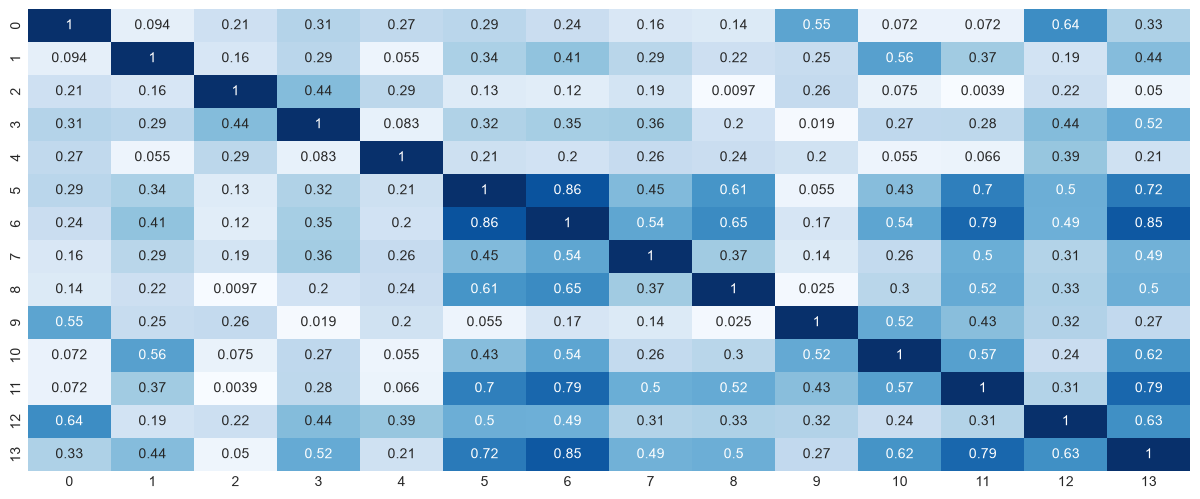

In [12]:
# Col: 13, [1 2 3] : classes
fig, ax = plt.subplots(figsize = (15,6))

sns.heatmap(data=df.corr().abs(), 
            ax=ax, 
            cmap='Blues', 
            annot=True,
            fmt='.2g',
            cbar=False)
            

In [13]:
labels = df[df.columns[-1]]
features_df = df.drop(df.columns[-1],axis=1)
features_df

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [14]:
X_train, X_test, y_train, y_test = train_test_split(features_df, labels,
                                                    test_size=TEST_SIZE,
                                                    random_state=RANDOM_STATE,
                                                    stratify=labels)

In [15]:
# Fit Transform on Train and Only Tranform on Test

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test )


In [16]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((142, 13), (36, 13), (142,), (36,))

In [17]:
y_train

array([1, 1, 1, 1, 2, 0, 0, 0, 1, 2, 1, 1, 0, 2, 0, 1, 0, 1, 0, 1, 0, 2,
       1, 0, 2, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 2, 0, 1, 2, 2, 1, 0,
       1, 1, 0, 2, 0, 1, 1, 2, 1, 2, 1, 1, 1, 0, 0, 2, 2, 0, 2, 0, 1, 1,
       2, 0, 0, 2, 0, 2, 2, 2, 2, 0, 1, 1, 1, 0, 2, 0, 0, 1, 2, 2, 2, 2,
       1, 1, 1, 0, 1, 2, 1, 2, 0, 2, 1, 0, 2, 1, 1, 1, 1, 1, 2, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 2, 0, 2, 1, 0, 1, 1, 1, 1, 1, 2, 2, 1,
       2, 1, 2, 1, 0, 1, 1, 0, 2, 2])

# Prepare Model

In [18]:
model = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(X_train.shape[1],)), # Input Layer
        
        tf.keras.layers.Dense(8, activation='relu'), # Hidden Layer

        tf.keras.layers.Dense(3) # Output Layer : we are not using activation function on last layer
    ]
)

### Sparse matrix representation only stores the non-zero values along with their row and column coordinates.

### A dense representation is the standard way you normally store and work with a matrix (like a 2D NumPy array or a Pandas DataFrame).

In [19]:
import sys
sys.float_info.min

2.2250738585072014e-308

In [20]:
sys.float_info.max

1.7976931348623157e+308

In [21]:
1.7976931348623157**308

2.833951766629345e+78

In [22]:
np.log(sys.float_info.max)

np.float64(709.782712893384)

In [23]:
X_train[:1]

array([[-0.02222104, -0.61751924,  0.85197806,  3.13822833,  2.89556415,
         1.63549206,  0.86441875, -1.2103246 ,  0.59041704, -0.74138556,
         1.52983005,  1.27292302,  0.73966546]])

In [24]:
prediction = model(X_train[:1])
prediction

<tf.Tensor: shape=(1, 3), dtype=float32, numpy=array([[-0.08484393, -0.49995154, -0.48337388]], dtype=float32)>

In [25]:
tf.nn.softmax(prediction).numpy().sum()

np.float32(1.0)

In [26]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 8)                   │             112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 139 (556.00 B)

 Trainable params: 139 (556.00 B)

 Non-trainable params: 0 (0.00 B)

In [27]:
13*8+8
# 13 inpcoming
# 8 outgoing
# 8 biases

112

In [28]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
loss_fn

optimizer = tf.keras.optimizers.Adam(learning_rate=ALPHA)



In [29]:
model.compile(optimizer=optimizer,
              loss=loss_fn,
              metrics=["accuracy"])

In [30]:
history = model.fit(X_train, y_train,
                    validation_data=[X_test,y_test],
                    epochs=EPOCHS)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.1972 - loss: 1.6288 - val_accuracy: 0.1389 - val_loss: 1.7938
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2113 - loss: 1.5746 - val_accuracy: 0.1389 - val_loss: 1.7326
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2183 - loss: 1.5232 - val_accuracy: 0.1667 - val_loss: 1.6731
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.2324 - loss: 1.4733 - val_accuracy: 0.1667 - val_loss: 1.6160
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.2324 - loss: 1.4254 - val_accuracy: 0.1667 - val_loss: 1.5614
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.2606 - loss: 1.3796 - val_accuracy: 0.2222 - val_loss: 1.5096
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.2887 - loss: 1.3359 - val_accuracy: 0.2778 - val_loss: 1.4600
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3239 - loss: 1.2938 - val_accuracy: 0.3056 - val_loss:

In [31]:
loss_df = pd.DataFrame(history.history)
loss_df

,accuracy,loss,val_accuracy,val_loss
0,0.197183,1.628820,0.138889,1.793781
1,0.211268,1.574623,0.138889,1.732555
2,0.218310,1.523168,0.166667,1.673138
3,0.232394,1.473312,0.166667,1.615983
4,0.232394,1.425398,0.166667,1.561372
...,...,...,...,...
95,0.964789,0.140852,0.944444,0.169854
96,0.964789,0.138711,0.944444,0.167489
97,0.964789,0.136601,0.972222,0.165199
98,0.964789,0.134506,0.972222,0.162964


In [32]:
def fn_plot_tf_hist(hist_df):
    
    '''
    Args:
        hist_df: a DataFrame with column names accuracy,loss	val_accuracy	val_loss
    '''
        
    fig, axes = plt.subplots(1,2 , figsize = (15,6))

    # properties  matplotlib.patch.Patch 
    props = dict(boxstyle='round', facecolor='aqua', alpha=0.4)
    facecolor = 'cyan'
    fontsize=12
    CMAP = plt.cm.coolwarm
    # Get columns by index to eliminate any column naming error
    y1 = hist_df.columns[0]
    y2 = hist_df.columns[1]
    y3 = hist_df.columns[2]
    y4 = hist_df.columns[3]

    # Where was min loss
    best = hist_df[hist_df[y4] == hist_df[y4].min()]
    
    ax = axes[0]

    hist_df.plot(y = [y2,y4], ax = ax, colormap=CMAP)


    # little beautification
    txtFmt = "Loss: \n  train: {:6.4f}\n   test: {:6.4f}"
    txtstr = txtFmt.format(hist_df.iloc[-1][y2],
                           hist_df.iloc[-1][y4]) #text to plot
    
    # place a text box in upper middle in axes coords
    ax.text(0.3, 0.95, txtstr, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)
    
    # calculate offset for arrow
    y_min = min(hist_df[y2].min(), hist_df[y4].min())
    y_max = max(hist_df[y2].max(), hist_df[y4].max())
    offset = (y_max-y_min)/10.0
    
    best_idx = best.index.to_numpy()[0]  # Extract first (and only) element as scalar
    best_value = best[y4].to_numpy()[0]   # Extract scalar value
    
    # Mark arrow at lowest
    ax.annotate(f'Min: {best_value:6.4f}', # text to print
                xy=(best_idx, best_value), # Arrow start
                xytext=(best_idx, best_value + offset), # location of text 
                fontsize=fontsize, va='bottom', ha='right',bbox=props, # beautification of text
                arrowprops=dict(facecolor=facecolor, shrink=0.05)) # arrow
    
    # Draw vertical line at best value
    ax.axvline(x = best_idx, color = 'green', linestyle='-.', lw = 3)

    ax.set_xlabel("Epochs")
    ax.set_ylabel(y2.capitalize())
    ax.set_title('Loss Curve')
    ax.grid(True)
    ax.legend(loc = 'upper left') # model legend to upper left
    
    ax = axes[1]

    hist_df.plot( y = [y1, y3], ax = ax, colormap=CMAP)
    
    # little beautification
    txtFmt = "Accuracy: \n  train: {:6.4f}\n  test:  {:6.4f}"
    txtstr = txtFmt.format(hist_df.iloc[-1][y1],
                           hist_df.iloc[-1][y3]) #text to plot

    # place a text box in upper middle in axes coords
    ax.text(0.3, 0.2, txtstr, transform=ax.transAxes, fontsize=fontsize,
            verticalalignment='top', bbox=props)

    # calculate offset for arroe
    y_min = min(hist_df[y1].min(), hist_df[y3].min())
    y_max = max(hist_df[y1].max(), hist_df[y3].max())
    offset = (y_max-y_min)/10.0

    best_value = best[y3].to_numpy()[0]   # Extract scalar value
    # Mark arrow at lowest
    ax.annotate(f'Best: {best_value:6.4f}', # text to print
                xy=(best_idx, best_value), # Arrow start
                xytext=(best_idx, best_value-offset), # location of text 
                fontsize=fontsize, va='bottom', ha='right',bbox=props, # beautification of text
                arrowprops=dict(facecolor=facecolor, shrink=0.05)) # arrow
    
    
    # Draw vertical line at best value
    ax.axvline(x = best_idx, color = 'green', linestyle='-.', lw = 3)

    ax.set_xlabel("Epochs")
    ax.set_ylabel(y1.capitalize())
    ax.set_title('Accuracy Curve')
    ax.grid(True)
    ax.legend(loc = 'lower left')
    
    plt.tight_layout()
    plt.show()

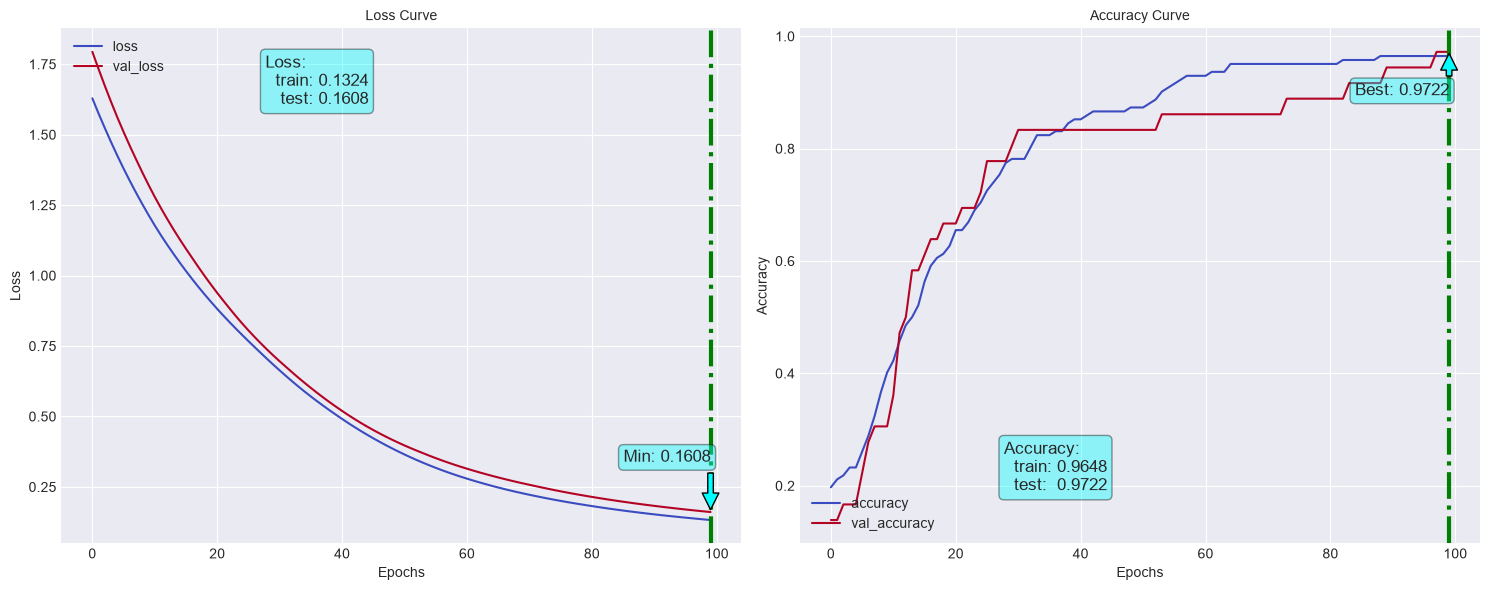

In [33]:
fn_plot_tf_hist(loss_df)

In [34]:
# Train Data

In [35]:
model.evaluate(X_train, y_train, verbose=2)

5/5 - 0s - 18ms/step - accuracy: 0.9648 - loss: 0.1311


[0.13106471300125122, 0.9647887349128723]

In [36]:
y_pred = model.predict(X_train)
y_pred.shape

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


(142, 3)

In [37]:
f1_sc = f1_score(y_true=y_train, y_pred = y_pred.argmax(axis=1),average='weighted')
print(f1_sc)
accuracy_score(y_train, y_pred.argmax(axis=1))

0.9648282401280049


0.9647887323943662

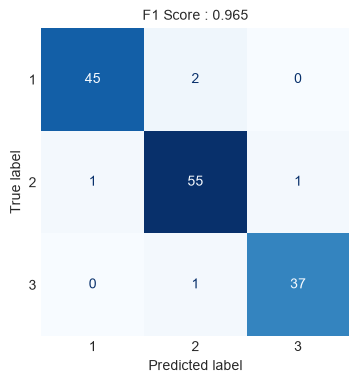

In [39]:
cm = confusion_matrix(y_train,y_pred.argmax(axis=1))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1,2,3])

fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax, cmap=plt.cm.Blues, colorbar=False)
plt.title(f"F1 Score : {f1_sc:0.3f}")
plt.grid()
plt.show()

In [40]:
# Test Data

In [41]:
y_pred = model.predict(X_test)
y_pred.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


(36, 3)

In [42]:
f1_sc = f1_score(y_true=y_test, y_pred = y_pred.argmax(axis=1),average='weighted')
print(f1_sc)
accuracy_score(y_test, y_pred.argmax(axis=1))

0.9722633744855966


0.9722222222222222

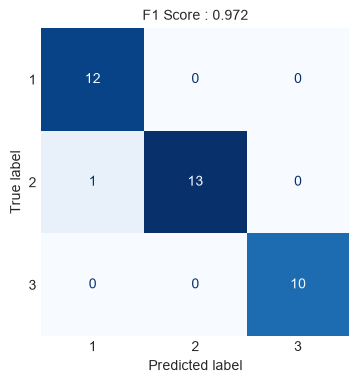

In [43]:
cm = confusion_matrix(y_test,y_pred.argmax(axis=1))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1,2,3])

fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax, cmap=plt.cm.Blues, colorbar=False)
plt.title(f"F1 Score : {f1_sc:0.3f}")
plt.grid()
plt.show()